# Session 4: Kai's waveform and unit-position workflow

This notebook uses **RF session 4 only**, with Kai's original `Utils/si_utils.py`, analysis defaults, export layout, and plot calls. Your units retain their original joint-sorting cluster IDs, so they can be matched to RF results.

Your data were sorted jointly across five recordings. The first steps prepare session-4-local **probe sample indices** and the file layout Kai's helper expects. The analysis then reads **session 4's raw ProbeA recording**, rather than the full concatenated recording. This preparation does not rerun sorting or change cluster labels.

Copy the accompanying files into the repository and restart the notebook kernel. From a terminal in the repository root, install the extras with `uv sync --extra analysis --extra waveform --link-mode copy`. Select the project's `.venv\Scripts\python.exe` as the notebook kernel.

In [1]:
from pathlib import Path
import csv
import sys

code_PATH = Path(r"R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping")
if not (code_PATH / "Utils" / "si_utils.py").is_file():
    raise FileNotFoundError(f"Repository helper not found under {code_PATH}")
sys.path.insert(0, str(code_PATH))

import Utils.si_utils as si_helpers
from Utils.si_utils import generate_unit_artifacts
from Utils.ad_prepare_waveform_session import inspect_session_inputs, prepare_session_inputs

print("Python:", sys.executable)
print("Kai's analysis helper:", si_helpers.__file__)

R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping\.venv\Scripts\python.exe
Kai's analysis helper: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping\Utils\si_utils.py


In [2]:
from pathlib import Path
import sys

print("Python:", sys.executable)
print("Working directory:", Path.cwd())
print("Repository exists:", code_PATH.is_dir())
print("Utils exists:", (code_PATH / "Utils").is_dir())
print("Helper exists:", (code_PATH / "Utils" / "si_utils.py").is_file())

Python: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping\.venv\Scripts\python.exe
Working directory: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping
Repository exists: True
Utils exists: True
Helper exists: True


## Configure your session

`session_number = 4` means folder `session_04` (RF split metadata uses zero-based ID 3). `only_good_units=True` preserves Kai's unit selection.

The original concatenation's `provenance.json` supplies the order of the five raw recordings. If its saved paths are unavailable on Windows, replace `raw_probe_files = None` with the **five ProbeA `continuous.dat` paths in their original concatenation order**. Do not infer the order from a directory listing.

In [3]:
data_PATH = Path(r"R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse")
mouseID = "m002"
pipeline_output_PATH = "small-spread-neuropixel-config"
date_PATH = "2026-09-25"
pipeline_session_output_PATH = "ad_session_2026_09_25"
date = "260925"
session_number = 4
session_id = str(session_number)
probe_name = "A"
only_good_units = True

base_dir = data_PATH / mouseID
day_dir = base_dir / pipeline_output_PATH / date_PATH
pipeline_dir = day_dir / pipeline_session_output_PATH
session_dir = pipeline_dir / "sessions" / f"session_{session_number:02d}"
data_dir = session_dir / "data"
concat_dir = pipeline_dir / f"Probe{probe_name}" / "concat"
joint_kilosort_dir = pipeline_dir / f"Probe{probe_name}" / "kilosort"

raw_session_dir = (
    day_dir / "20260925_HeadFixed-360-RFMappingSquares"
    / "AD_2026-09-25_15-42-01"
)
expected_raw_file = (
    raw_session_dir / "Record Node 102" / "experiment1" / "recording1"
    / "continuous" / "OneBox-104.ProbeA" / "continuous.dat"
)
raw_probe_files = None  # Or an explicit ordered list of all five raw ProbeA paths.

print("RF session:", session_dir)
print("Session-4 raw probe:", expected_raw_file)
print("Kai's output directory:", data_dir)

RF session: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04
Session-4 raw probe: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\20260925_HeadFixed-360-RFMappingSquares\AD_2026-09-25_15-42-01\Record Node 102\experiment1\recording1\continuous\OneBox-104.ProbeA\continuous.dat
Kai's output directory: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04\data


## Inspect the recording order and sample boundaries

This cell reads metadata without creating analysis inputs. It checks that the fourth source is your RF recording, that all five probe recordings match the saved concat, and that their lengths add up exactly.

Session boundaries come from **native probe frame counts**. ADC seconds and the ADC's sample offsets cannot substitute for these probe sample indices.

In [4]:
input_plan = inspect_session_inputs(
    concat_dir=concat_dir,
    joint_kilosort_dir=joint_kilosort_dir,
    session_dir=session_dir,
    session_number=session_number,
    expected_raw_file=expected_raw_file,
    probe_name=probe_name,
    raw_probe_files=raw_probe_files,
)

offset = 0
for number, (raw_file, count) in enumerate(
    zip(input_plan["raw_files"], input_plan["recording_lengths"]), start=1
):
    print(f"Session {number}: {count:,} probe frames; concat [{offset:,}, {offset + count:,})")
    print(" ", raw_file)
    offset += count
identity = input_plan["identity"]
print("Selected session:", session_number)
print("Probe sampling rate (Hz):", input_plan["fs"])
print("Selected spike count:", f"{identity['row_stop'] - identity['row_start']:,}")
print("Prepared sorting destination:", input_plan["target_kilosort_dir"])

Session 1: 70,295,746 probe frames; concat [0, 70,295,746)
  \\fsmresfiles.fsm.northwestern.edu\FSMResfiles\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\20260925_Free-360-withLandmarks\AD_2026-09-25_13-55-35\Record Node 102\experiment1\recording1\continuous\OneBox-104.ProbeA\continuous.dat
Session 2: 88,011,655 probe frames; concat [70,295,746, 158,307,401)
  \\fsmresfiles.fsm.northwestern.edu\FSMResfiles\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\20260925_Free-360-withStarsMoving\AD_2026-09-25_14-43-30\Record Node 102\experiment1\recording1\continuous\OneBox-104.ProbeA\continuous.dat
Session 3: 200,542,036 probe frames; concat [158,307,401, 358,849,437)
  \\fsmresfiles.fsm.northwestern.edu\FSMResfiles\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\20260925_Free-OpenField-Foraging\AD_2026-09-25_09-51-17\Record Node 103\experiment

## Prepare the session-local inputs

This writes `session_04/kilosort/ProbeA/kilosort_4/` and `session_04/data/session_info.json`, which Kai's helper already understands. It selects joint spikes within session 4 and subtracts the start of that **probe** recording. Cluster IDs, labels, and channel geometry are copied from the joint sorting. Raw recordings and joint sorting files remain the sources.

Matching prepared inputs can be reused. An existing sorting directory with different or unmanaged inputs raises an error rather than being replaced. These are analysis inputs for SpikeInterface, not a complete Phy editing export.

In [5]:
prepared_kilosort_dir = prepare_session_inputs(input_plan)
print("Session-local inputs:", prepared_kilosort_dir)

Session-local spike count: 3760558
Probe sample offset: 358849437
Kai's session metadata: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04\data\session_info.json
Session-local inputs: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04\kilosort\ProbeA\kilosort_4


## Run Kai's analysis

The shared analysis helper is unchanged. It keeps Kai's defaults: snippets from -0.5 to +1.5 ms, up to 2,000 sampled spikes per unit with seed 0, average templates, and PTP center-of-mass localization within 75 micrometers of the strongest contact. His default worker count is 32.

This computes one average waveform and one estimated probe position per unit **using session 4's spikes only**. Generation saves the waveform/position data and analyzer cache automatically.

In [6]:
artifact_paths = generate_unit_artifacts(
    base_dir=base_dir,
    probe_name=probe_name,
    date=date,
    session_id=session_id,
    session_dir=session_dir,
    output_dir=data_dir,
    only_good_units=only_good_units,
)
print(artifact_paths)

----- Working on ProbeA -----


estimate_templates_with_accumulator (workers: 24 processes spawn): 100%|██████████| 2252/2252 [03:03<00:00, 12.30it/s]


Analyzer Done
--------------------
Gen unit waveform
Exported waveform data: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04\data\waveform\ProbeA
--------------------
Gen unit position
Exported unit positions: R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\ad_session_2026_09_25\sessions\session_04\data\spike_position\ProbeA
UnitArtifactPaths(waveform_dir=WindowsPath('R:/Basic_Sciences/Phys/SenzaiLab/Aparna/Data_by_mouse/m002/small-spread-neuropixel-config/2026-09-25/ad_session_2026_09_25/sessions/session_04/data/waveform/ProbeA'), spike_position_dir=WindowsPath('R:/Basic_Sciences/Phys/SenzaiLab/Aparna/Data_by_mouse/m002/small-spread-neuropixel-config/2026-09-25/ad_session_2026_09_25/sessions/session_04/data/spike_position/ProbeA'), analyzer_dir=WindowsPath('R:/Basic_Sciences/Phys/SenzaiLab/Aparna/Data_by_mouse/m002/small-spread-neuropixel-

## Choose units and display Kai's plots

The initial selection uses the first available cluster ID in `units.csv`; replace `plot_unit_ids` with the IDs you want to inspect. This replaces the original notebook's example ID 280 without changing the analysis.

`save_figures=False` displays plots. Set it to `True`, then rerun the setup cell below and the plot cell to save Kai's usual PNGs under `data/waveform/ProbeA/figures/`. The same filenames are overwritten on a later save. This setting controls figures only; analysis data were already saved above.

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

from Utils.probe_plotting import WaveformUnitPlotCollection

analysis_dir = data_dir / 'waveform' / f"Probe{probe_name}"
with (analysis_dir / "units.csv").open(newline="") as handle:
    available_unit_ids = [int(row["unit_id"]) for row in csv.DictReader(handle)]
if not available_unit_ids:
    raise ValueError("No units were exported. Check the generation output.")
print("Available cluster IDs:", available_unit_ids)

plot_unit_ids = available_unit_ids[:5]
# Replace the line above with existing IDs, for example: plot_unit_ids = [12, 47]
if not plot_unit_ids or not set(plot_unit_ids).issubset(available_unit_ids):
    raise ValueError("Choose a nonempty list of available cluster IDs.")

save_figures = False

unit_plots = WaveformUnitPlotCollection(
    analysis_dir,
    plot_unit_ids,
    save_figures=save_figures,
)

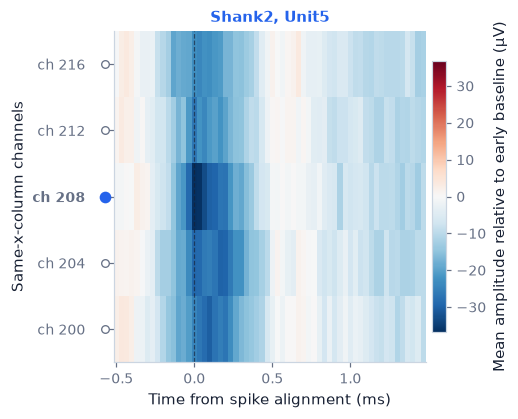

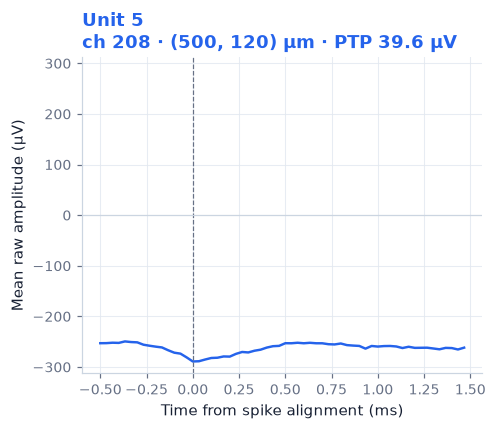

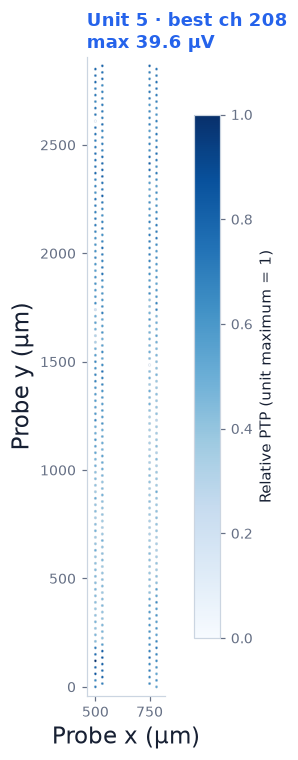

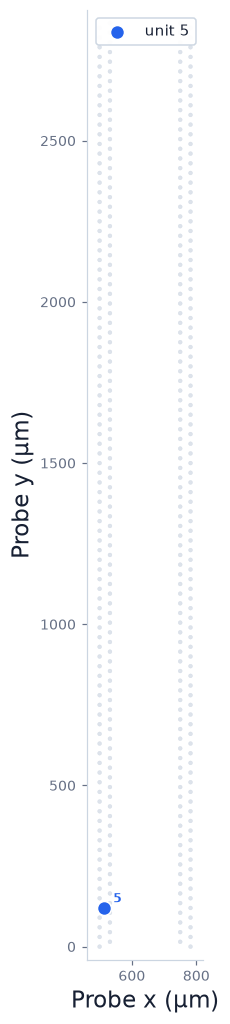

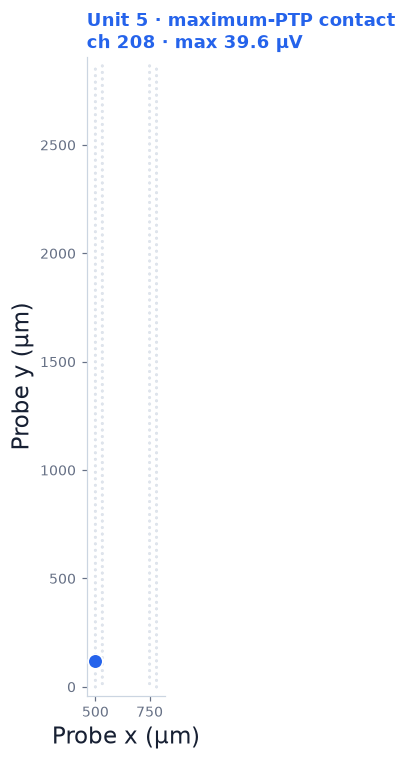

In [8]:
unit_plots.plot_local_average_heatmaps(local_channel_mode='same_x_column', )
unit_plots.plot_best_channel_averages()
unit_plots.plot_ptp_gradients()
unit_plots.plot_unit_locations(show_other_units=False)
max_contact_result = unit_plots.plot_max_ptp_contacts(
    layout='panels',
    show_other_units=False,
)

In [ ]:
unit_plots

## Saved results and later browsing

Under `session_04/data/`:

- `spikeinterface_analyzer/ProbeA/`: Kai's reusable analyzer cache.
- `waveform/ProbeA/`: `units.csv`, channel/time tables, manifests, and per-unit mean templates, PTP values, and spike sample tables.
- `spike_position/ProbeA/positions.csv`: original `unit_id` with estimated `x_um` and `y_um` in probe coordinates.
- `waveform/ProbeA/figures/`: the five original plot types, saved as 200-dpi PNGs when requested.

The original root `config.json` and `run.log` files are also retained under `waveform/` and `spike_position/`.

For later browsing, run imports/configuration, then the unit-selection and plotting cells. Input preparation and analysis generation do not need to be repeated just to change the plotted IDs or save figures. After re-sorting, prepare inputs against that new sorting and rebuild the analyzer explicitly; a matching ID alone does not establish that an old cache is current.

Link RF results to positions using **`unit_id`**, rather than CSV row number or `unit_index`. Positions are estimates in probe coordinates, not histological region assignments or a position for every individual spike.